<a href="https://colab.research.google.com/github/ajsid09/nifty-earnings-revision-engine/blob/main/Earning_revision_engine_project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
!pip install yfinance --upgrade -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.3/149.3 kB 5.9 MB/s eta 0:00:00


In [9]:
import yfinance as yf
print("yfinance version:", yf.__version__)

t = yf.Ticker("AAPL")

print("\n--- EPS TREND (how the estimate has moved) ---")
print(t.eps_trend)

print("\n--- EPS REVISIONS (how many analysts moved) ---")
print(t.eps_revisions)

yfinance version: 1.7.0

--- EPS TREND (how the estimate has moved) ---
        current  7daysAgo  30daysAgo  60daysAgo  90daysAgo currency
period                                                             
0q      1.97850   1.97865    1.97754    1.97549    2.00825      USD
+1q     2.91006   2.90586    2.91090    2.90495    2.94960      USD
0y      8.82011   8.82022    8.81228    8.80411    8.75950      USD
+1y     9.58043   9.57579    9.57132    9.55399    9.68261      USD

--- EPS REVISIONS (how many analysts moved) ---
        upLast7days  upLast30days  downLast30days  downLast7Days currency
period                                                                   
0q                1             7              14              0      USD
+1q               0             1               2              1      USD
0y                1             3               2              2      USD
+1y               0             5               3              1      USD


In [10]:
for sym in ["RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "INFY.NS", "ITC.NS", "MARUTI.NS"]:
    try:
        df = yf.Ticker(sym).eps_trend
        ok = df is not None and not df.empty and df.notna().any().any()
        print(f"{sym:15} -> {'DATA OK' if ok else 'EMPTY'}")
    except Exception as e:
        print(f"{sym:15} -> FAILED: {type(e).__name__}")

RELIANCE.NS     -> DATA OK
TCS.NS          -> DATA OK
HDFCBANK.NS     -> DATA OK
INFY.NS         -> DATA OK
ITC.NS          -> DATA OK
MARUTI.NS       -> DATA OK


In [11]:
r = yf.Ticker("RELIANCE.NS")
print(r.eps_trend)
print(r.eps_revisions)

         current  7daysAgo  30daysAgo  60daysAgo  90daysAgo currency
period                                                              
0q      12.30000     0.000    0.00000    0.00000       0.00      INR
+1q     17.49000    17.655   17.65500   17.65500      17.26      INR
0y      33.26667    29.950   25.83333   25.46667      29.95      INR
+1y     28.10000    29.450   26.00000   25.83333      29.45      INR
        upLast7days  upLast30days  downLast30days  downLast7Days currency
period                                                                   
0q                0             0               1              1      INR
+1q               0             0               1              1      INR
0y                2             3               2              1      INR
+1y               2             2               1              0      INR


In [12]:
NIFTY50 = [
 "RELIANCE","TCS","HDFCBANK","ICICIBANK","INFY","HINDUNILVR","ITC","SBIN",
 "BHARTIARTL","BAJFINANCE","KOTAKBANK","LT","HCLTECH","AXISBANK","ASIANPAINT",
 "MARUTI","SUNPHARMA","TITAN","ULTRACEMCO","WIPRO","ONGC","NTPC","POWERGRID",
 "NESTLEIND","M&M","TATAMOTORS","TATASTEEL","JSWSTEEL","ADANIENT","ADANIPORTS",
 "COALINDIA","BAJAJFINSV","GRASIM","HINDALCO","DRREDDY","CIPLA","APOLLOHOSP",
 "BRITANNIA","EICHERMOT","HEROMOTOCO","TECHM","INDUSINDBK","BPCL","SBILIFE",
 "HDFCLIFE","TATACONSUM","SHRIRAMFIN","LTIM","BAJAJ-AUTO","DIVISLAB",
]
TICKERS = [s + ".NS" for s in NIFTY50]
print(len(TICKERS), "tickers")

50 tickers


In [13]:
import pandas as pd, time, datetime as dt

def fetch_one(sym):
    t = yf.Ticker(sym)
    trend = t.eps_trend
    if trend is None or trend.empty:
        return None
    trend = trend.drop(columns=["currency"], errors="ignore")
    try:
        rev = t.eps_revisions
        if rev is not None and not rev.empty:
            rev = rev.drop(columns=["currency"], errors="ignore")
            trend = trend.join(rev, how="left")
    except Exception:
        pass
    out = trend.reset_index()
    out = out.rename(columns={out.columns[0]: "period"})
    out.insert(0, "ticker", sym)
    return out

In [14]:
rows, failed = [], []
for i, sym in enumerate(TICKERS, 1):
    try:
        d = fetch_one(sym)
        rows.append(d) if d is not None else failed.append(sym)
    except Exception:
        failed.append(sym)
    print(f"{i}/{len(TICKERS)}  {sym:18}", end="\r")
    time.sleep(1.0)

snap = pd.concat(rows, ignore_index=True)
snap.insert(0, "snapshot_date", dt.date.today().isoformat())

print(f"\nOK: {snap.ticker.nunique()} tickers | Failed: {failed}")
snap.head(12)

ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TATAMOTORS.NS"}}}


ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: LTIM.NS"}}}



OK: 48 tickers | Failed: ['TATAMOTORS.NS', 'LTIM.NS']


,snapshot_date,ticker,period,current,7daysAgo,30daysAgo,60daysAgo,90daysAgo,upLast7days,upLast30days,downLast30days,downLast7Days
0,2026-10-11,RELIANCE.NS,0q,12.30000,0.00000,0.00000,0.00000,0.00000,0.0,0.0,1.0,1.0
1,2026-10-11,RELIANCE.NS,+1q,17.49000,17.65500,17.65500,17.65500,17.26000,0.0,0.0,1.0,1.0
2,2026-10-11,RELIANCE.NS,0y,33.26667,29.95000,25.83333,25.46667,29.95000,2.0,3.0,2.0,1.0
3,2026-10-11,RELIANCE.NS,+1y,28.10000,29.45000,26.00000,25.83333,29.45000,2.0,2.0,1.0,0.0
4,2026-10-11,TCS.NS,0q,38.31464,38.77160,38.63308,38.62721,38.62721,0.0,0.0,1.0,1.0
5,2026-10-11,TCS.NS,+1q,39.16383,39.61096,39.38557,39.37054,39.37054,0.0,0.0,1.0,1.0
6,2026-10-11,TCS.NS,0y,154.12631,154.48132,155.08232,155.00272,154.83566,1.0,2.0,2.0,0.0
7,2026-10-11,TCS.NS,+1y,161.20804,162.16966,162.49910,162.42776,162.27513,0.0,1.0,2.0,1.0
8,2026-10-11,HDFCBANK.NS,0q,12.49400,12.24000,12.24000,12.46000,12.04000,1.0,1.0,0.0,0.0
9,2026-10-11,HDFCBANK.NS,+1q,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
for c in ["TMPV.NS","LTM.NS","TMLCV.NS","TMCVL.NS","TMCV.NS","TATAMOTORS.BO"]:
    try:
        d = yf.Ticker(c).eps_trend
        print(f"{c:16} -> {'OK' if d is not None and not d.empty else 'EMPTY'}")
    except Exception as e:
        print(f"{c:16} -> {type(e).__name__}")

TMPV.NS          -> OK
LTM.NS           -> OK


ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TMLCV.NS"}}}


TMLCV.NS         -> EMPTY


ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TMCVL.NS"}}}


TMCVL.NS         -> EMPTY
TMCV.NS          -> OK


ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TATAMOTORS.BO"}}}


TATAMOTORS.BO    -> EMPTY


In [16]:
NIFTY50 = [t for t in NIFTY50 if t not in ("TATAMOTORS","LTIM")] + ["TMPV","LTM"]
TICKERS = [s + ".NS" for s in NIFTY50]

In [17]:
from google.colab import drive; drive.mount('/content/drive')
import os
OUT = "/content/drive/MyDrive/revision_engine"
os.makedirs(OUT, exist_ok=True)
path = f"{OUT}/snapshot_{dt.date.today().isoformat()}.csv"
snap.to_csv(path, index=False)
print("saved:", path, "|", snap.shape)

Mounted at /content/drive
saved: /content/drive/MyDrive/revision_engine/snapshot_2026-10-11.csv | (192, 12)


In [18]:
rc = snap[snap.period == "0y"]
print("tickers with revision counts:",
      rc[["upLast30days","downLast30days"]].notna().all(axis=1).sum(), "/", len(rc))
print("tickers with any analyst movement in 30d:",
      ((rc.upLast30days.fillna(0) + rc.downLast30days.fillna(0)) > 0).sum())

tickers with revision counts: 48 / 48
tickers with any analyst movement in 30d: 48


In [19]:
fy = snap[snap.period == "0y"].copy()
fy["chg_90d_pct"] = (fy["current"] / fy["90daysAgo"] - 1) * 100
print("Non-null 90d values:", fy["90daysAgo"].notna().sum(), "/", len(fy))
print("Tickers where estimate actually moved:", (fy.chg_90d_pct.abs() > 0.01).sum())
print(fy[["ticker","current","90daysAgo","chg_90d_pct"]]
        .sort_values("chg_90d_pct", ascending=False).head(10))

Non-null 90d values: 48 / 48
Tickers where estimate actually moved: 47
            ticker    current  90daysAgo  chg_90d_pct
14    ICICIBANK.NS   79.24975    0.00000          inf
30         SBIN.NS   90.32116    0.00000          inf
54     AXISBANK.NS  103.34318    0.00000          inf
62       MARUTI.NS  446.81635    0.00000          inf
110    ADANIENT.NS   42.30333   31.00000    36.462355
162  INDUSINDBK.NS   56.03280   45.80294    22.334505
2      RELIANCE.NS   33.26667   29.95000    11.074023
126      GRASIM.NS  125.32484  115.47308     8.531651
190    DIVISLAB.NS  123.55598  114.31645     8.082415
70        TITAN.NS   72.05071   67.75968     6.332719


In [20]:
import numpy as np
LOOKBACKS = ["7daysAgo","30daysAgo","60daysAgo","90daysAgo"]
snap_c = snap.copy()
snap_c[["current"] + LOOKBACKS] = snap_c[["current"] + LOOKBACKS].replace(0, np.nan)
print("zeros removed:", (snap[LOOKBACKS] == 0).sum().sum())

zeros removed: 79


In [21]:
def build_signals(df, period="0y"):
    d = df[df.period == period].copy()
    for lb, col in [("7d","7daysAgo"), ("30d","30daysAgo"), ("90d","90daysAgo")]:
        d[f"mag_{lb}"] = (d["current"] / d[col] - 1) * 100
    up = d["upLast30days"].fillna(0)
    dn = d["downLast30days"].fillna(0)
    tot = up + dn
    d["breadth_30d"] = np.where(tot > 0, (up - dn) / tot, np.nan)
    d["n_revisions"] = tot
    return d

sig = build_signals(snap_c, "0y")
print(sig[["mag_7d","mag_30d","mag_90d","breadth_30d"]].describe().round(2))

       mag_7d  mag_30d  mag_90d  breadth_30d
count   42.00    43.00    42.00        48.00
mean     0.51     1.68     0.52         0.12
std      2.34     7.57     9.77         0.64
min     -1.96    -5.56   -34.89        -1.00
25%     -0.27    -0.66    -1.60        -0.20
50%     -0.01     0.01    -0.45         0.06
75%      0.35     0.41     2.19         0.61
max     11.07    39.16    36.46         1.00


In [22]:
for t in ["ADANIENT.NS","INDUSINDBK.NS","RELIANCE.NS"]:
    print(snap_c[snap_c.ticker == t][
        ["ticker","period","current","7daysAgo","30daysAgo","60daysAgo","90daysAgo",
         "upLast30days","downLast30days"]].to_string(index=False), "\n")

     ticker period  current  7daysAgo  30daysAgo  60daysAgo  90daysAgo  upLast30days  downLast30days
ADANIENT.NS     0q 13.62000  10.19000   10.19000   10.19000      7.810           1.0             0.0
ADANIENT.NS    +1q 13.28000  13.05000   13.05000   13.05000      8.970           1.0             0.0
ADANIENT.NS     0y 42.30333  42.30333   30.40000   42.84000     31.000           0.0             1.0
ADANIENT.NS    +1y 65.84000  65.84000   67.38667   64.38667     56.585           1.0             1.0 

       ticker period  current  7daysAgo  30daysAgo  60daysAgo  90daysAgo  upLast30days  downLast30days
INDUSINDBK.NS     0q  11.3800   9.50500    9.50500    8.71000    8.42000           0.0             1.0
INDUSINDBK.NS    +1q  12.8300  12.85000   12.85000   10.93000   12.74000           0.0             1.0
INDUSINDBK.NS     0y  56.0328  55.93953   55.92829   55.98666   45.80294           2.0             1.0
INDUSINDBK.NS    +1y  78.5404  78.48396   78.46128   78.54470   70.95532         

In [23]:
def zscore(s, lo_q=0.05, hi_q=0.95, clip=3):
    s = s.astype(float)
    s = s.clip(s.quantile(lo_q), s.quantile(hi_q))
    return ((s - s.mean()) / s.std(ddof=0)).clip(-clip, clip)

# Ensure 'snap_c' exists before building signals
if 'snap_c' not in globals() and 'snap' in globals():
    import numpy as np
    LOOKBACKS = ["7daysAgo","30daysAgo","60daysAgo","90daysAgo"]
    snap_c = snap.copy()
    snap_c[["current"] + LOOKBACKS] = snap_c[["current"] + LOOKBACKS].replace(0, np.nan)

# Ensure 'sig' exists in the namespace before calling zscore on it
if 'sig' not in globals() and 'snap_c' in globals():
    sig = build_signals(snap_c, "0y")

sig["z_mag_30d"]  = zscore(sig["mag_30d"])
sig["z_mag_90d"]  = zscore(sig["mag_90d"])
sig["z_breadth"]  = zscore(sig["breadth_30d"])

Z = ["z_mag_30d","z_mag_90d","z_breadth"]
sig[Z] = sig[Z].fillna(0)   # missing = neutral, not bullish or bearish

In [24]:
W = {"z_mag_30d": 0.40, "z_mag_90d": 0.30, "z_breadth": 0.30}
sig["score"] = sum(sig[c] * w for c, w in W.items())
sig["rank"] = sig["score"].rank(ascending=False).astype(int)

out = sig.sort_values("score", ascending=False)[
    ["rank","ticker","mag_30d","mag_90d","breadth_30d","n_revisions","score"]].round(3)
print("TOP 10\n", out.head(10).to_string(index=False))
print("\nBOTTOM 10\n", out.tail(10).to_string(index=False))

TOP 10
  rank        ticker  mag_30d  mag_90d  breadth_30d  n_revisions  score
    1     GRASIM.NS    8.596    8.532        1.000          6.0  2.084
    2   RELIANCE.NS   28.774   11.074        0.200          5.0  1.843
    3   ADANIENT.NS   39.156   36.462       -1.000          1.0  1.277
    4         LT.NS    4.674    4.674        0.000          2.0  0.880
    5   DIVISLAB.NS    0.255    8.082        1.000         26.0  0.805
    6      TITAN.NS    0.369    6.333        1.000          6.0  0.726
    7 INDUSINDBK.NS    0.187   22.335        0.333          3.0  0.641
    8 ASIANPAINT.NS   -0.017    6.227        0.857         28.0  0.588
    9  NESTLEIND.NS   -0.079    5.291        0.935         31.0  0.562
   10  COALINDIA.NS    1.837    1.005        0.600          5.0  0.482

BOTTOM 10
  rank        ticker  mag_30d  mag_90d  breadth_30d  n_revisions  score
   39     MARUTI.NS      NaN      NaN       -0.939         33.0 -0.498
   40       BPCL.NS   -0.863  -34.887        0.667       

In [25]:
import numpy as np

LB = ["7daysAgo","30daysAgo","60daysAgo","90daysAgo"]
snap_c = snap.copy()
snap_c[["current"]+LB] = snap_c[["current"]+LB].replace(0, np.nan)

def zscore(s, clip=3):
    s = s.astype(float)
    s = s.clip(s.quantile(.05), s.quantile(.95))
    return ((s - s.mean()) / s.std(ddof=0)).clip(-clip, clip)

d = snap_c[snap_c.period == "0y"].copy()
for lb, col in [("30d","30daysAgo"), ("90d","90daysAgo")]:
    d[f"mag_{lb}"] = (d["current"]/d[col] - 1) * 100

up = d["upLast30days"].fillna(0); dn = d["downLast30days"].fillna(0)
d["n_rev"]    = up + dn
d["brd_raw"]  = np.where(d.n_rev > 0, (up-dn)/d.n_rev, np.nan)
d["brd"]      = (up - dn) / (up + dn + 8.0)          # shrinkage, k=8

d["mag"] = np.where(np.sign(d.mag_30d) == np.sign(d.mag_90d),
                    (d.mag_30d + d.mag_90d)/2, 0.0)

d["suspect"] = ((d.mag.abs() > 10) & (d.n_rev < 5)) | \
               ((d.mag > 5) & (d.brd_raw.fillna(0) <= 0))
print("flagged:", d.loc[d.suspect,"ticker"].tolist())
d.loc[d.suspect, "mag"] = np.nan

d["z_mag"] = zscore(d["mag"]); d["z_brd"] = zscore(d["brd"])
d[["z_mag","z_brd"]] = d[["z_mag","z_brd"]].fillna(0)
d["score"] = 0.55*d.z_mag + 0.45*d.z_brd
d["rank"]  = d.score.rank(ascending=False).astype(int)

cols = ["rank","ticker","mag_30d","mag_90d","mag","brd_raw","brd","n_rev","score"]
res = d.sort_values("score", ascending=False)[cols].round(3)
print("\nTOP 10\n", res.head(10).to_string(index=False))
print("\nBOTTOM 10\n", res.tail(10).to_string(index=False))

flagged: ['ADANIENT.NS', 'INDUSINDBK.NS']

TOP 10
  rank        ticker  mag_30d  mag_90d    mag  brd_raw   brd  n_rev  score
    1   DIVISLAB.NS    0.255    8.082  4.169    1.000 0.765   26.0  1.826
    2     GRASIM.NS    8.596    8.532  8.564    1.000 0.429    6.0  1.652
    3      TITAN.NS    0.369    6.333  3.351    1.000 0.429    6.0  1.388
    4   RELIANCE.NS   28.774   11.074 19.924    0.200 0.077    5.0  1.133
    5         LT.NS    4.674    4.674  4.674    0.000 0.000    2.0  1.019
    6  NESTLEIND.NS   -0.079    5.291  0.000    0.935 0.744   31.0  0.907
    6 ASIANPAINT.NS   -0.017    6.227  0.000    0.857 0.667   28.0  0.907
    8 HEROMOTOCO.NS   -0.060    2.555  0.000    0.630 0.486   27.0  0.733
    9 APOLLOHOSP.NS    0.070    1.850  0.960    0.444 0.308   18.0  0.682
   10  COALINDIA.NS    1.837    1.005  1.421    0.600 0.231    5.0  0.670

BOTTOM 10
  rank        ticker  mag_30d  mag_90d     mag  brd_raw    brd  n_rev  score
   39 HINDUNILVR.NS    0.015   -0.063   0.000  

In [26]:
d["mag"] = np.where(
    np.sign(d.mag_30d) == np.sign(d.mag_90d),
    np.sign(d.mag_30d) * np.minimum(d.mag_30d.abs(), d.mag_90d.abs()),
    0.0)
d.loc[d.n_rev < 3, "mag"] = 0.0
d.loc[d.suspect, "mag"] = np.nan

d["z_mag"] = zscore(d["mag"]); d["z_brd"] = zscore(d["brd"])
d[["z_mag","z_brd"]] = d[["z_mag","z_brd"]].fillna(0)
d["score"] = 0.55*d.z_mag + 0.45*d.z_brd
d["rank"]  = d.score.rank(ascending=False).astype(int)

res = d.sort_values("score", ascending=False)[
    ["rank","ticker","mag","brd","n_rev","score"]].round(3)
print(res.head(10).to_string(index=False))
print(res.tail(10).to_string(index=False))

 rank        ticker    mag   brd  n_rev  score
    1     GRASIM.NS  8.532 0.429    6.0  1.576
    2  COALINDIA.NS  1.005 0.231    5.0  1.205
    3   DIVISLAB.NS  0.255 0.765   26.0  1.160
    4   RELIANCE.NS 11.074 0.077    5.0  1.057
    4    HCLTECH.NS  1.138 0.077    5.0  1.057
    6      TITAN.NS  0.369 0.429    6.0  0.992
    7 ASIANPAINT.NS  0.000 0.667   28.0  0.958
    7  NESTLEIND.NS  0.000 0.744   31.0  0.958
    9 HEROMOTOCO.NS  0.000 0.486   27.0  0.784
   10  KOTAKBANK.NS  0.386 0.273    3.0  0.776
 rank        ticker    mag    brd  n_rev  score
   39        TCS.NS -0.458  0.000    4.0 -0.296
   40   HDFCLIFE.NS -0.704 -0.077    5.0 -0.605
   41 ULTRACEMCO.NS -1.062  0.000    6.0 -0.775
   42     MARUTI.NS  0.000 -0.756   33.0 -0.840
   43   JSWSTEEL.NS -1.961  0.161   23.0 -1.200
   44   HDFCBANK.NS -5.557  0.067    7.0 -1.340
   45  TATASTEEL.NS -0.806 -0.613   23.0 -1.477
   46        M&M.NS -1.095 -0.611   28.0 -1.703
   47    DRREDDY.NS -1.715 -0.784   29.0 -2.200
   

In [27]:
from scipy.stats import spearmanr

px = yf.download(d.ticker.tolist(), period="6mo",
                 auto_adjust=True, progress=False)["Close"]
fwd = (px.iloc[-1] / px.iloc[-22] - 1) * 100      # ~last 21 trading days

lag = snap_c[snap_c.period == "0y"].set_index("ticker")
bt = d[["ticker","n_rev"]].copy()
bt["sig_lag"] = (lag["30daysAgo"]/lag["90daysAgo"] - 1).reindex(bt.ticker).values * 100
bt["fwd_ret"] = fwd.reindex(bt.ticker).values
bt = bt.replace([np.inf,-np.inf], np.nan).dropna(subset=["sig_lag","fwd_ret"])

rho, p = spearmanr(bt.sig_lag, bt.fwd_ret)
print(f"n={len(bt)}  rho={rho:.3f}  p={p:.3f}")

bt["bucket"] = pd.qcut(bt.sig_lag.rank(method="first"), 5,
                       labels=["Q1 low","Q2","Q3","Q4","Q5 high"])
print(bt.groupby("bucket", observed=True).fwd_ret
        .agg(["mean","median","count"]).round(2))
print("Q5 - Q1 spread:",
      round(bt[bt.bucket=="Q5 high"].fwd_ret.mean()
          - bt[bt.bucket=="Q1 low"].fwd_ret.mean(), 2), "%")

n=43  rho=-0.170  p=0.275
         mean  median  count
bucket                      
Q1 low  -4.23   -5.21      9
Q2      -5.08   -5.91      8
Q3      -5.44   -5.68      9
Q4      -6.89   -5.89      8
Q5 high -6.59   -8.21      9
Q5 - Q1 spread: -2.36 %


In [28]:
bt["excess"] = bt.fwd_ret - bt.fwd_ret.mean()
rho_e, p_e = spearmanr(bt.sig_lag, bt.excess)
print(f"market-neutral: rho={rho_e:.3f} p={p_e:.3f}")

for w in [5, 10, 21, 42, 63]:
    r = (px.iloc[-1]/px.iloc[-1-w] - 1).reindex(bt.ticker).values*100
    rr, pp = spearmanr(bt.sig_lag, r, nan_policy="omit")
    print(f"{w:>3}d horizon: rho={rr:+.3f}  p={pp:.3f}")

market-neutral: rho=-0.170 p=0.275
  5d horizon: rho=-0.035  p=0.823
 10d horizon: rho=-0.037  p=0.814
 21d horizon: rho=-0.170  p=0.275
 42d horizon: rho=-0.183  p=0.240
 63d horizon: rho=+0.209  p=0.179


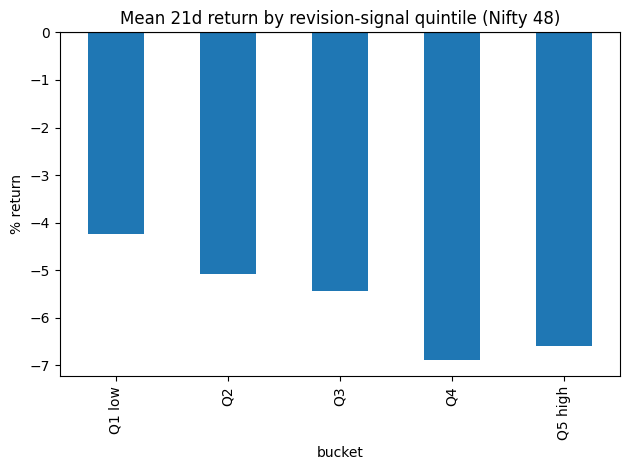

In [29]:
import matplotlib.pyplot as plt
b = bt.groupby("bucket", observed=True).fwd_ret.mean()
b.plot(kind="bar", title="Mean 21d return by revision-signal quintile (Nifty 48)")
plt.ylabel("% return"); plt.axhline(0, c="k", lw=.8); plt.tight_layout()
plt.savefig(f"{OUT}/quintiles.png", dpi=150); plt.show()

In [30]:
xl = f"{OUT}/revision_engine_{dt.date.today().isoformat()}.xlsx"
with pd.ExcelWriter(xl, engine="openpyxl") as w:
    res.to_excel(w, "Scores", index=False)
    bt.round(3).to_excel(w, "Backtest", index=False)
    pd.DataFrame({
        "Item": ["Universe","Source","Signal","Cleaning","Test","Result","Limitations"],
        "Detail": [
            "Nifty 50 (48 resolved; TATAMOTORS→TMPV, LTIM→LTM)",
            "Yahoo Finance consensus FY1 EPS via yfinance (free)",
            "0.55 x magnitude z-score + 0.45 x shrunk breadth z-score",
            "Zeros→NaN; breadth shrunk k=8; sign-consistency across 30d/90d; "
            "panel-change flag (large move, <5 analysts or non-positive breadth)",
            "Signal lagged 30d vs forward returns, Spearman + quintiles",
            "rho -0.17 (21d), p=0.275; sign unstable across 5-63d horizons; "
            "no detectable predictive power",
            "n=48, single overlapping period, no power; Mar-FY rollover not handled; "
            "survivorship bias from current-day ticker list; weights unfitted"]
    }).to_excel(w, "Methodology", index=False)
print("saved:", xl)

saved: /content/drive/MyDrive/revision_engine/revision_engine_2026-10-11.xlsx


/tmp/ipykernel_875/3847053874.py:3: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  res.to_excel(w, "Scores", index=False)
/tmp/ipykernel_875/3847053874.py:4: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  bt.round(3).to_excel(w, "Backtest", index=False)
/tmp/ipykernel_875/3847053874.py:18: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  }).to_excel(w, "Methodology", index=False)
